# **Lab 2 – Tidying, Cleaning, Imputation, and Outlier Detection**

## Machine Learning Programming

This assignment continues the work started in **`week5Lab.ipynb`**.  
Open this notebook and complete the activities **in this notebook**, preserving the section order and the overall structure.

The purpose of this lab is to practice the data-preprocessing work that normally takes place before machine learning: reshaping data, cleaning inconsistent values, handling missing data, detecting outliers, visualizing results, and explaining the decisions you make.

## **Assignment Overview**

### Purpose
By the end of this lab, you should be able to take several imperfect datasets and make them more suitable for analysis and later machine-learning work.

### Learning Outcomes
You will practice how to:

- inspect the shape, columns, data types, and quality of a dataset;
- distinguish **wide** and **long/tidy** data;
- reshape data with `pd.melt()` or `DataFrame.melt()`;
- clean strings using Pandas string methods;
- identify, quantify, drop, and impute missing values;
- compare mean, median, mode, and `SimpleImputer` approaches;
- identify outliers visually with box plots and scatter plots;
- identify outliers statistically using **Z-Scores** and **IQR**;
- justify preprocessing decisions using evidence from the data;
- document a reproducible Python data-processing workflow.

### Estimated Completion Time
Approximately **2.5–3.5 hours**, depending on your Python experience.

## **Submission and Project Structure**

Keep the project organized so another person can reproduce your work.

Recommended structure:

```text
project/
├── week5Lab.ipynb
├── README.md
├── requirements.txt
├── .gitignore
└── data/
    ├── pew-raw.csv
    ├── billboard.csv
    ├── cars.csv
    └── diabetes.csv
```

A clearly named equivalent data folder such as `CSVs/` or `datasets/` is also acceptable if all notebook paths are updated consistently.

### Required submission artifacts

- `week5Lab.ipynb` containing **all four completed sections**
- `README.md` with at least 1–2 meaningful sentences describing the lab and how to run it
- `requirements.txt` containing the packages required to reproduce the environment
- `.gitignore`
- all required data files inside a clearly named data folder

**Important:** Use relative paths such as `./data/cars.csv`. Do not use absolute paths from your own computer.

**Environment practice:** Use `requirements.txt` to define the environment. Do not add `!pip install ...` cells to the notebook when a requirements file is provided.

## **Before You Begin**

Use the following libraries where appropriate:

- `pandas`
- `numpy`
- `matplotlib`
- `seaborn`
- `scikit-learn`

Run the import cell below before beginning the exercises.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer

# Optional display settings
pd.set_option("display.max_columns", None)

## **General Expectations**

For every section:

1. Write the required Python code.
2. Display enough output to demonstrate that the code works.
3. Add short Markdown explanations in your own words.
4. Label plots clearly with a title and axis labels.
5. Explain what the output means instead of only producing it.
6. Preserve the required section headings so the notebook is easy to follow.
7. Before submitting, restart the kernel and use **Run All** to confirm the notebook executes from beginning to end.

### Replicability Testing

Our group used a shared GitHub repository to collaborate on this assignment. Team members cloned the repository and used `requirements.txt` to install the necessary dependencies on their computers.

The testing process and results are documented in the **Replicability Check** section at the end of this notebook.

# **Section 1 – PEW Research Dataset**

## **Learning Topic: Data Tidying and Reshaping**

A dataset is commonly described as **tidy** when:

1. each variable forms a column;
2. each observation forms a row; and
3. each type of observational unit forms a table.

The PEW dataset represents counts for religions across income ranges. In its original form, income values appear as column headings. You will reshape the dataset from **wide** format to **long/tidy** format using `melt()`.

### Required concepts
- dataset inspection
- wide versus long data
- identifier variables
- measured variables
- `pd.melt()` or `DataFrame.melt()`
- visualization after reshaping

## **Getting the PEW Dataset from the Internet**

For this lab, use the small **PEW religion-and-income dataset** commonly used to demonstrate tidy-data principles. This is the dataset whose first column is `religion` and whose remaining columns are income ranges such as `<$10k`, `$10-20k`, and `$20-30k`.

### Recommended method — download in your browser

1. Open the dataset in a browser:
   `https://raw.githubusercontent.com/nickhould/tidy-data-python/master/data/pew-raw.csv`
2. Save the file as **`pew-raw.csv`**.
3. Create a folder named **`data`** in the same project folder as this notebook if it does not already exist.
4. Move `pew-raw.csv` into the `data` folder.
5. Confirm that your project contains:

```text
project/
├── week5Lab.ipynb
└── data/
    └── pew-raw.csv
```

6. Load the local copy with:

```python
df_pew = pd.read_csv("./data/pew-raw.csv")
```

### Optional Python-assisted download

The following is an example only. You may use it once to obtain the dataset, but your submitted analysis should subsequently read the **local copy** from `./data/`.

```python
from pathlib import Path
import pandas as pd

Path("data").mkdir(exist_ok=True)

url = "https://raw.githubusercontent.com/nickhould/tidy-data-python/master/data/pew-raw.csv"
df_pew = pd.read_csv(url)
df_pew.to_csv("./data/pew-raw.csv", index=False)
```

### Verify before continuing

After loading the file, check that the dataframe contains a `religion` column and multiple income-range columns. If it does not, stop and verify that you downloaded the correct dataset.

> **Good reproducibility practice:** Do not depend on the Internet every time the notebook runs. Download the dataset once, store it in the project's `data/` folder, commit the permitted data file to your repository, and use a relative path in the notebook.

### **Task 1.1 – Load and Inspect the Dataset**

1. Load the PEW dataset from your data folder.
2. Display its shape.
3. Display its column names.
4. Display several rows using `head()`, `loc`, `iloc`, or `tail()`.
5. Identify the column that should remain the identifier variable.

1. Load the PEW dataset from your data folder.

In [2]:
import pandas as pd

df = pd.read_csv("data/messy_survey_wide_50k.csv")

2. Display its shape

In [3]:
df.shape

(50000, 50)

3. Display its column names:
The columns include:
- respondent_id, province, interview_date
- wk1 through wk26
- q1_a through q1_e
- Income columns, such as inc_<$20k and inc_$80-100k
- Household demographic columns, such as hh_m_0_14 and hh_f_65plus

In [4]:
df.columns.tolist()

['respondent_id',
 'province',
 'interview_date',
 'wk1',
 'wk2',
 'wk3',
 'wk4',
 'wk5',
 'wk6',
 'wk7',
 'wk8',
 'wk9',
 'wk10',
 'wk11',
 'wk12',
 'wk13',
 'wk14',
 'wk15',
 'wk16',
 'wk17',
 'wk18',
 'wk19',
 'wk20',
 'wk21',
 'wk22',
 'wk23',
 'wk24',
 'wk25',
 'wk26',
 'q1_a',
 'q1_b',
 'q1_c',
 'q1_d',
 'q1_e',
 'inc_<$20k',
 'inc_$20-40k',
 'inc_$40-60k',
 'inc_$60-80k',
 'inc_$80-100k',
 'inc_>$100k',
 'hh_m_0_14',
 'hh_m_15_24',
 'hh_m_25_44',
 'hh_m_45_64',
 'hh_m_65plus',
 'hh_f_0_14',
 'hh_f_15_24',
 'hh_f_25_44',
 'hh_f_45_64',
 'hh_f_65plus']

4. Display several rows

In [5]:
df.head()

,respondent_id,province,interview_date,wk1,wk2,wk3,wk4,wk5,wk6,wk7,...,hh_m_0_14,hh_m_15_24,hh_m_25_44,hh_m_45_64,hh_m_65plus,hh_f_0_14,hh_f_15_24,hh_f_25_44,hh_f_45_64,hh_f_65plus
0,1000001,QC,2024-05-09,72.35,NaN,76.40,NaN,160.98,293.60,117.93,...,NaN,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
1,1000002,BC,2024-08-03,NaN,48.72,74.04,156.76,146.66,NaN,276.99,...,1.0,2.0,1.0,0.0,NaN,1.0,0.0,0.0,0.0,1.0
2,1000003,QC,2024-05-31,174.81,NaN,8.62,31.42,NaN,78.92,19.70,...,1.0,NaN,0.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0
3,1000004,ON,2024-12-30,170.78,79.47,NaN,NaN,64.29,110.58,267.88,...,1.0,0.0,NaN,1.0,0.0,NaN,0.0,0.0,2.0,NaN
4,1000005,ON,2024-02-27,NaN,NaN,77.17,102.94,36.90,127.14,NaN,...,0.0,1.0,0.0,0.0,0.0,2.0,1.0,0.0,1.0,NaN


5. Identify the column that should remain the identifier variable

In [6]:
df["respondent_id"].head()

0    1000001
1    1000002
2    1000003
3    1000004
4    1000005
Name: respondent_id, dtype: int64

In [7]:
df["respondent_id"].is_unique

True

### **Task 1.3 – Reshape with `melt()`**

Use either of these valid Pandas forms:

```python
pd.melt(...)
```

or

```python
df.melt(...)
```

Your result should have meaningful names for the new variable and value columns, such as `income` and `count`.

### 1. Clean the dirty `province` values

In [8]:
print("Before:", sorted(df["province"].unique()))
df["province"] = df["province"].str.strip().str.upper()
print("After: ", sorted(df["province"].unique()))

Before: [' ON ', 'AB', 'BC', 'MB', 'NB', 'NL', 'NS', 'ON', 'PE', 'QC', 'SK', 'on']
After:  ['AB', 'BC', 'MB', 'NB', 'NL', 'NS', 'ON', 'PE', 'QC', 'SK']


### 2. Week number stored in headers: `wk1` ... `wk26`  ->  `week`, `spend`

In [9]:
import pandas as pd

#df = pd.read_csv("data/messy_survey_wide_50k.csv")

# Melt only the weekly columns, keeping respondent_id as identifier
wk_cols = [c for c in df.columns if c.startswith("wk")]

weekly_spending = df.melt(
    id_vars=["respondent_id", "province"],   # province now travels with each row
    value_vars=wk_cols,
    var_name="week",
    value_name="spend",
).dropna(subset=["spend"])

weekly_spending["week"] = weekly_spending["week"].str.replace("wk", "").astype(int)
weekly_spending = weekly_spending.sort_values(["respondent_id", "week"]).reset_index(drop=True)
print(weekly_spending.shape)    # (779314, 4)
weekly_spending.head()

(779314, 4)


,respondent_id,province,week,spend
0,1000001,QC,1,72.35
1,1000001,QC,3,76.40
2,1000001,QC,5,160.98
3,1000001,QC,6,293.60
4,1000001,QC,7,117.93


In [10]:
# TODO: Compare the original and reshaped tables.
print("Original shape:", df.shape)
print("Reshaped shape:", weekly_spending.shape)
weekly_spending.to_csv("data/long_weekly_spend.csv", index=False)

Original shape: (50000, 50)
Reshaped shape: (779314, 4)


### **Task 1.4 – Visualize the Tidy Data**

Create at least **one meaningful visualization** from the reshaped dataset.

Possible questions include:

- How do counts differ across income groups?
- How do selected religions compare across income groups?

Your plot must include a title and axis labels.

Plot 1 (counts across spend groups): every province has nearly the same mix. About 30% of weekly records are low spend, about 35% medium, about 19% high and about 15% very high. Ontario ranges from 30.4% to 15.3% across the groups, and every other province is within a point or so of it.

In [11]:
if "weekly_spending" not in globals():
    source_df = pd.read_csv("data/messy_survey_wide_50k.csv")
    wk_cols = [col for col in source_df.columns if col.startswith("wk")]
    weekly_spending = source_df.melt(
        id_vars=["respondent_id", "province"],
        value_vars=wk_cols,
        var_name="week",
        value_name="spend",
    ).dropna(subset=["spend"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

# Plot 1: distribution of weekly spending (from the long weekly_spending table)
ax[0].hist(weekly_spending["spend"], bins=40, color="#1F2A44", edgecolor="white")
ax[0].axvline(weekly_spending["spend"].mean(), color="#B8924A", ls="--",
              label=f"Mean = ${weekly_spending['spend'].mean():.0f}")
ax[0].set_title("Distribution of Weekly Spending")
ax[0].set_xlabel("Weekly spend ($)")
ax[0].set_ylabel("Number of weekly records")
ax[0].legend()

# Plot 2: respondents by province (from the original respondent table)
counts = weekly_spending.drop_duplicates("respondent_id")["province"].value_counts()
ax[1].bar(counts.index, counts.values, color="#B8924A")
ax[1].set_title("Respondents by Province")
ax[1].set_xlabel("Province")
ax[1].set_ylabel("Number of respondents")

stats_by_prov = weekly_spending.groupby("province")["spend"].agg(["mean", "std", "count"])
stats_by_prov["ci95"] = 1.96 * stats_by_prov["std"] / np.sqrt(stats_by_prov["count"])
stats_by_prov = stats_by_prov.sort_values("mean")

overall_mean = weekly_spending["spend"].mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(stats_by_prov["mean"], stats_by_prov.index, xerr=stats_by_prov["ci95"],
            fmt="o", color="#1F2A44", ecolor="#B8924A", elinewidth=2, capsize=4)
ax.axvline(overall_mean, color="grey", ls="--", label=f"Overall mean = ${overall_mean:.2f}")

ax.set_title("Average Weekly Spend by Province (with 95% Confidence Intervals)")
ax.set_xlabel("Average weekly spend ($)")
ax.set_ylabel("Province")
ax.legend()
ax.grid(axis="x", alpha=0.3)


plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

### **Task 1.5 – PEW Reflection**

Answer **all** questions briefly in your own words:

1. What was the main structural problem with the original dataset?
2. What does `id_vars` mean in `melt()`?
3. What information moved from columns into rows?
4. How did the number of rows change after reshaping, and why?
5. Why is the long format easier to analyze or visualize?
6. What did your visualization reveal?

## Reflection: Week Number Stored in Headers (`wk1` … `wk26` → `week`, `spend`)

1. **Main structural problem:** 
- The week number was stored in the column names (`wk1` … `wk26`), so 26 columns held the same variable, weekly spending.

2. **`id_vars`:** 
- These are the columns that stay fixed during `melt()`. Here it is `respondent_id` (and `province`), so each spending value stays linked to its respondent.

3. **What moved from columns into rows:** 
- The week labels. `wk1`, `wk2`, … became values in a new `week` column, and the amounts went into a new `spend` column.

4. **Change in rows:** 
- The data grew from 50,000 rows to 779,314 rows. Melting 26 columns gives 1,300,000 rows (50,000 × 26), but about 40% of the cells were empty, and dropping them leaves 779,314.

5. **Why long format is easier:** 
- All spending is in one column, so one command works (`groupby("week")`, `groupby("province")`, or one histogram) instead of handling 26 separate columns.

6. **What the visualization revealed:** 
- Weekly spending is right-skewed with a mean of about $90, and it is nearly identical across provinces and weeks. There is no clear province or time effect in this synthetic data.

# **Section 2 – Billboard Dataset**

**Dataset source:** [Billboard-Hot-100 repository](https://github.com/hajimariyam/Billboard-Hot-100)

**Important:** This source contains weekly chart records in a long format (one row per song appearance in a weekly chart). The original classic Billboard file was wide, with one column per week. To practise both `pivot()` and `melt()` meaningfully, this notebook creates a compact wide table from the long data using `pivot()`, then uses `melt()` to return to long format. The original source rows are retained separately.

## 2.1. Data source and setup

Download the CSV from the direct link below and save it inside the `data` folder as `charts_top50_2001_2020.csv`. The loading cell checks both locations.

- [Download the full Billboard Top 50 CSV (2001–2020)](https://raw.githubusercontent.com/hajimariyam/Billboard-Hot-100/main/charts_top50_2001_2020.csv)
- Repository documentation says the data is separated into three CSV files by period and sorted newest to oldest, then by rank.

In [12]:
from pathlib import Path
import re
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


billboard_raw = pd.read_csv("./data/billboard.csv", encoding="unicode_escape")
print("Raw shape:", billboard_raw.shape)

Raw shape: (52150, 7)


## 2.2. Inspect and standardize the schema

Inspect the actual column names before writing cleaning logic. The next cell standardizes column labels for easier coding without changing the meaning of the fields.

In [13]:
print("Columns:", billboard_raw.columns.tolist())
display(billboard_raw.head())
display(billboard_raw.info())

Columns: ['date', 'rank', 'song', 'artist', 'last-week', 'peak-rank', 'weeks-on-board']


,date,rank,song,artist,last-week,peak-rank,weeks-on-board
0,12/26/2020,1,Willow,Taylor Swift,NaN,1,1
1,12/26/2020,2,All I Want For Christmas Is You,Mariah Carey,1.0,1,42
2,12/26/2020,3,Rockin' Around The Christmas Tree,Brenda Lee,3.0,2,37
3,12/26/2020,4,Jingle Bell Rock,Bobby Helms,5.0,3,34
4,12/26/2020,5,Mood,24kGoldn Featuring iann dior,2.0,1,19


<class 'pandas.DataFrame'>
RangeIndex: 52150 entries, 0 to 52149
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            52150 non-null  str    
 1   rank            52150 non-null  int64  
 2   song            52150 non-null  str    
 3   artist          52150 non-null  str    
 4   last-week       50501 non-null  float64
 5   peak-rank       52150 non-null  int64  
 6   weeks-on-board  52150 non-null  int64  
dtypes: float64(1), int64(3), str(3)
memory usage: 2.8 MB


None

In [14]:
billboard = billboard_raw.copy()

def standardize_column_name(column):
    column = str(column).strip().lower()
    column = re.sub(r"[^a-z0-9]+", "_", column)
    return column.strip("_")

billboard.columns = [standardize_column_name(c) for c in billboard.columns]

print("Standardized columns:", billboard.columns.tolist())
display(billboard.head())

Standardized columns: ['date', 'rank', 'song', 'artist', 'last_week', 'peak_rank', 'weeks_on_board']


,date,rank,song,artist,last_week,peak_rank,weeks_on_board
0,12/26/2020,1,Willow,Taylor Swift,NaN,1,1
1,12/26/2020,2,All I Want For Christmas Is You,Mariah Carey,1.0,1,42
2,12/26/2020,3,Rockin' Around The Christmas Tree,Brenda Lee,3.0,2,37
3,12/26/2020,4,Jingle Bell Rock,Bobby Helms,5.0,3,34
4,12/26/2020,5,Mood,24kGoldn Featuring iann dior,2.0,1,19


## 2.3. Initial EDA

Review row counts, column types, numeric summaries, and missing values before making any cleaning decisions.

In [15]:
print(f"Rows: {len(billboard):,}")
print(f"Columns: {billboard.shape[1]:,}")
display(billboard.dtypes.to_frame("dtype"))
display(billboard.describe(include="all").T)
missing_summary = (
    billboard.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_percent=lambda x: (x["missing_count"] / len(billboard) * 100).round(2))
    .sort_values("missing_count", ascending=False)
)
display(missing_summary)

Rows: 52,150
Columns: 7


,dtype
date,str
rank,int64
song,str
artist,str
last_week,float64
peak_rank,int64
weeks_on_board,int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,52150,1043,12/26/2020,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rank,52150.0,NaN,NaN,NaN,25.5,14.431008,1.0,13.0,25.5,38.0,50.0
song,52150,3915,Rockstar,105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artist,52150,2124,Taylor Swift,701,NaN,NaN,NaN,NaN,NaN,NaN,NaN
last_week,50501.0,NaN,NaN,NaN,25.941447,15.949158,1.0,13.0,25.0,38.0,100.0
peak_rank,52150.0,NaN,NaN,NaN,16.941841,14.282851,1.0,4.0,13.0,28.0,50.0
weeks_on_board,52150.0,NaN,NaN,NaN,15.84581,10.53846,1.0,8.0,14.0,21.0,87.0


,missing_count,missing_percent
last_week,1649,3.16
rank,0,0.00
date,0,0.00
song,0,0.00
artist,0,0.00
peak_rank,0,0.00
weeks_on_board,0,0.00


### Findings and Reflection

The Billboard dataset contains 52,150 rows and 7 columns. The data types and descriptive statistics provide an overview of the available variables and their distributions.

The missing-value analysis shows that the `last_week` column contains 1,649 missing values, representing 3.16% of the records. The other six columns have no missing values. Missing values in `last_week` may indicate that a song entered the chart without a previous-week ranking, so they should be investigated before deciding how to handle them.

This initial EDA helps identify potential data-quality issues and guides the next steps in data cleaning, string manipulation, and reshaping. The original dataset is already in long format, so a sample can be used to demonstrate `pivot()` and `melt()` for the assignment's tidying requirement.

## 2.4. Identify the data structure and field meanings

This CSV represents weekly chart appearances rather than one row per unique song. Check whether date, current rank, song, and artist fields are present. The schema guard below avoids silently applying later code to an unexpected file.

In [ ]:
required_any = {
    "date": ["date", "chart_date", "chart_week"],
    "song": ["song", "track", "title"],
    "artist": ["artist", "artist_name"],
    "current_rank": ["this_week", "thisweek", "rank", "current_rank", "position"],
    "previous_rank": ["last_week", "lastweek", "previous_rank"],
    "peak_rank": ["peak_position", "peak", "peak_rank"],
    "weeks_on_chart": ["weeks_on_chart", "weeks", "weeks_on_chart"],
    
    #"weeks_on_chart": ["weeks_on_chart", "weeks_on_board", "weeks"]
}

resolved = {}
for field, options in required_any.items():
    match = next((name for name in options if name in billboard.columns), None)
    resolved[field] = match

display(pd.DataFrame({"logical_field": list(resolved), "matched_column": list(resolved.values())}))

for field in ["song", "artist", "current_rank"]:
    if resolved[field] is None:
        raise ValueError(
            f"Could not identify the {field!r} column. Check the printed schema "
            "and update the mapping options for this source file."
        )

,logical_field,matched_column
0,date,date
1,song,song
2,artist,artist
3,current_rank,rank
4,previous_rank,last_week
5,peak_rank,peak_rank
6,weeks_on_chart,NaN


### Findings and Reflection

The schema validation confirms that the dataset contains the expected fields for date, song, artist, current rank, previous rank, and peak rank. The `weeks_on_chart` field was not matched because the dataset uses the column name `weeks_on-board` rather than the alternatives defined in the code.

The matched columns are `date`, `song`, `artist`, `rank`, `last_week`, and `peak_rank`. These fields provide information about when a song appeared on the chart, its current and previous rankings, and its highest ranking.

This check is useful because it identifies differences between the expected field names and the actual dataset schema before further processing. The column mapping should be updated to recognize `weeks_on-board` so that all seven fields can be identified correctly.

## 2.5. Data-quality checks

Check exact duplicate rows, missing values in key identifiers, and unexpected rank values. A valid chart position is typically between 1 and 100 for the Billboard Hot 100, while this source file focuses on Top 50 entries.

In [17]:
duplicate_rows = int(billboard.duplicated().sum())
print("Exact duplicate rows:", duplicate_rows)

key_cols = [resolved["song"], resolved["artist"]]
if resolved["date"]:
    key_cols.append(resolved["date"])

print("Missing key-field values:")
display(billboard[key_cols].isna().sum().to_frame("missing_count"))

rank_col = resolved["current_rank"]
billboard[rank_col] = pd.to_numeric(billboard[rank_col], errors="coerce")
print("Current-rank values outside 1–100:")
display(billboard.loc[~billboard[rank_col].between(1, 100), [rank_col]].head(10))

Exact duplicate rows: 0
Missing key-field values:


,missing_count
song,0
artist,0
date,0


Current-rank values outside 1–100:


,rank


### Findings and reflection

The data-quality checks found 0 exact duplicate rows in the Billboard dataset. The key fields song, artist, and date each contain 0 missing values, indicating that these essential fields are complete for identifying chart appearances.

The current-rank validation also found no values outside the range of 1–100. Therefore, all current rankings pass this validation check.

These results suggest that the dataset has no exact duplicate rows or missing values in its key identifier fields, and its current rankings fall within the expected range. However, the earlier EDA identified 1,649 missing values in the last_week column (3.16% of records). These should be investigated because a missing previous-week rank may occur when a song first enters the chart.

Overall, the checks provide a useful baseline for data quality before proceeding with further cleaning, string manipulation, feature engineering, and reshaping using melt().

## 2.6. Cleaning and validation

The cleaning process keeps the raw DataFrame intact, trims text, converts dates and numeric columns when they can be identified, and removes only exact duplicate records. Missing previous-week rank values are not automatically imputed because a blank can mean a song was not on the chart the previous week.

In [18]:
clean = billboard.copy()

# Trim leading/trailing whitespace from text fields.
text_cols = clean.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    clean[col] = clean[col].astype("string").str.strip()

# Parse the date column if one was identified.
date_col = resolved["date"]
if date_col:
    clean[date_col] = pd.to_datetime(clean[date_col], errors="coerce")

# Convert ranking/count columns when available.
numeric_fields = ["current_rank", "previous_rank", "peak_rank", "weeks_on_chart"]
for field in numeric_fields:
    col = resolved.get(field)
    if col and col in clean.columns:
        clean[col] = pd.to_numeric(clean[col], errors="coerce")

before = len(clean)
clean = clean.drop_duplicates().copy()
print(f"Removed {before - len(clean):,} exact duplicate rows.")
print("Clean shape:", clean.shape)
display(clean.head())

Removed 0 exact duplicate rows.
Clean shape: (52150, 7)


,date,rank,song,artist,last_week,peak_rank,weeks_on_board
0,2020-12-26,1,Willow,Taylor Swift,NaN,1,1
1,2020-12-26,2,All I Want For Christmas Is You,Mariah Carey,1.0,1,42
2,2020-12-26,3,Rockin' Around The Christmas Tree,Brenda Lee,3.0,2,37
3,2020-12-26,4,Jingle Bell Rock,Bobby Helms,5.0,3,34
4,2020-12-26,5,Mood,24kGoldn Featuring iann dior,2.0,1,19


In [19]:
# Validate cleaning: report missingness and data types again.
display(clean.isna().sum().to_frame("missing_after_cleaning"))
display(clean.dtypes.to_frame("dtype_after_cleaning"))

,missing_after_cleaning
date,0
rank,0
song,0
artist,0
last_week,1649
peak_rank,0
weeks_on_board,0


,dtype_after_cleaning
date,datetime64[us]
rank,int64
song,string
artist,string
last_week,float64
peak_rank,int64
weeks_on_board,int64


### Findings and Reflection

The cleaning and validation process removed **0 exact duplicate rows**, so the dataset retained all **52,150 rows and 7 columns**. Leading and trailing whitespace was trimmed from text fields, the `date` column was converted to a datetime data type, and the ranking-related columns were converted to numeric types where applicable.

After cleaning, the missing-value check showed that the `last_week` column still contains **1,649 missing values**, while all other columns have no missing values. These missing values were retained rather than automatically imputed because a missing previous-week ranking may indicate that a song was not on the chart in the preceding week.

The updated data types confirm that `date` is stored as `datetime64`, `rank` and `peak_rank` are integers, and `last_week` is a floating-point column because it contains missing values. The `song` and `artist` columns are stored as strings.

Overall, the cleaning process improved data consistency while preserving meaningful missing values and the original raw dataset. The cleaned DataFrame is now ready for further exploratory analysis, feature engineering, and reshaping with `melt()`.

## 2.7. Missing-value analysis

Compare missingness in the previous-week rank with missingness in the current rank. A missing previous-week value can be meaningful for a new chart entry; a missing current rank is more problematic for a row that purports to be a chart appearance.


In [20]:
for field in ["current_rank", "previous_rank", "peak_rank", "weeks_on_chart"]:
    col = resolved.get(field)
    if col and col in clean.columns:
        print(f"{field} ({col}): {clean[col].isna().sum():,} missing values")

previous_col = resolved.get("previous_rank")
if previous_col:
    print("Rows with missing previous-week rank:", int(clean[previous_col].isna().sum()))

current_rank (rank): 0 missing values
previous_rank (last_week): 1,649 missing values
peak_rank (peak_rank): 0 missing values
Rows with missing previous-week rank: 1649


## 2.8. Feature engineering and string manipulation

Create useful date features and a rank-change feature. Positive `rank_improvement` means the song moved to a smaller (better) rank number compared with the previous week. If the previous rank is missing, the change remains missing rather than being guessed.

In [21]:
features = clean.copy()

if date_col:
    features["chart_year"] = features[date_col].dt.year
    features["chart_month"] = features[date_col].dt.month
    features["chart_day_name"] = features[date_col].dt.day_name()

current_col = resolved["current_rank"]
previous_col = resolved.get("previous_rank")
if previous_col:
    # Positive values mean improvement: previous rank minus current rank.
    features["rank_improvement"] = features[previous_col] - features[current_col]

song_col = resolved["song"]
artist_col = resolved["artist"]
features["song_clean"] = features[song_col].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
features["artist_clean"] = features[artist_col].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()

display(features.head())

,date,rank,song,artist,last_week,peak_rank,weeks_on_board,chart_year,chart_month,chart_day_name,rank_improvement,song_clean,artist_clean
0,2020-12-26,1,Willow,Taylor Swift,NaN,1,1,2020,12,Saturday,NaN,Willow,Taylor Swift
1,2020-12-26,2,All I Want For Christmas Is You,Mariah Carey,1.0,1,42,2020,12,Saturday,-1.0,All I Want For Christmas Is You,Mariah Carey
2,2020-12-26,3,Rockin' Around The Christmas Tree,Brenda Lee,3.0,2,37,2020,12,Saturday,0.0,Rockin' Around The Christmas Tree,Brenda Lee
3,2020-12-26,4,Jingle Bell Rock,Bobby Helms,5.0,3,34,2020,12,Saturday,1.0,Jingle Bell Rock,Bobby Helms
4,2020-12-26,5,Mood,24kGoldn Featuring iann dior,2.0,1,19,2020,12,Saturday,-3.0,Mood,24kGoldn Featuring iann dior


## 2.9. EDA: chart rankings and potential outliers

Use plots and summary statistics to explore the current chart rank and rank changes. Because chart rank is bounded and its meaning is ordinal, extreme ranks are not automatically data errors. Investigate unusual values instead of deleting them by default.

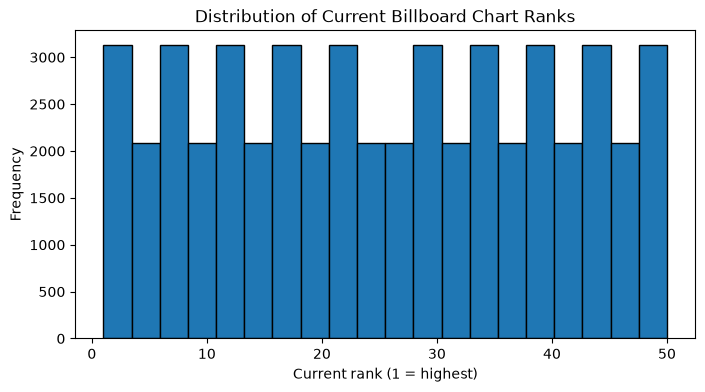

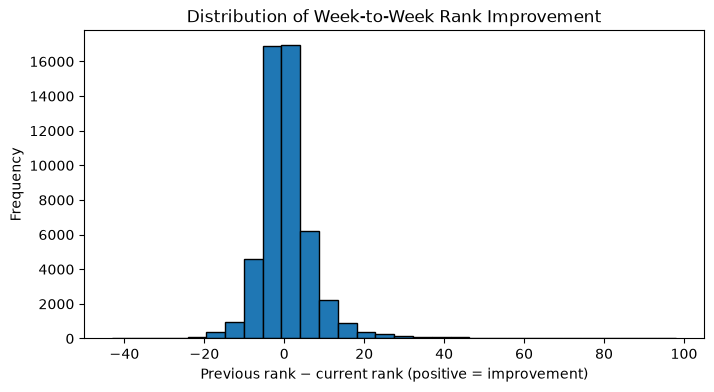

,count,mean,std,min,25%,50%,75%,max
rank,52150.0,25.50000,14.431008,1.0,13.0,25.5,38.0,50.0
rank_improvement,50501.0,0.54494,7.633199,-43.0,-3.0,0.0,3.0,98.0


In [22]:
plt.figure(figsize=(8, 4))
features[current_col].dropna().plot(kind="hist", bins=20, edgecolor="black")
plt.title("Distribution of Current Billboard Chart Ranks")
plt.xlabel("Current rank (1 = highest)")
plt.ylabel("Frequency")
plt.show()

if "rank_improvement" in features.columns:
    plt.figure(figsize=(8, 4))
    features["rank_improvement"].dropna().plot(kind="hist", bins=30, edgecolor="black")
    plt.title("Distribution of Week-to-Week Rank Improvement")
    plt.xlabel("Previous rank − current rank (positive = improvement)")
    plt.ylabel("Frequency")
    plt.show()

display(features[[current_col] + (["rank_improvement"] if "rank_improvement" in features.columns else [])].describe().T)

### Findings and Reflection

The histogram of current Billboard chart rankings shows an approximately uniform distribution across ranks 1–50. This pattern is expected because the dataset records Top 50 chart entries for each chart date, with each rank represented regularly.

The distribution of `rank_improvement` is concentrated around zero, indicating that many songs experience relatively small changes in their rankings from one week to the next. Positive values represent improvements in ranking, while negative values indicate declines. The histogram also shows some larger changes, suggesting that certain songs move substantially up or down the chart between weeks.

The summary statistics show that `rank_improvement` has 50,501 non-missing observations, compared with 52,150 current-rank observations. This difference is consistent with the missing previous-week rankings identified earlier. These missing values were excluded from the rank-improvement histogram rather than being estimated.

Overall, the visualizations help describe chart-position patterns and week-to-week movements. Extreme ranking changes should be investigated in context rather than automatically treated as data errors or removed from the dataset.

## 2.10. Practise `pivot()` and `melt()` using a song-week table

The source CSV is already long format. To demonstrate both reshaping operations, create a stable song identifier, pivot a small selection of songs into one column per chart date, and melt that table back to long format. This is an instructional transformation; the original `features` table remains unchanged.

If multiple rows exist for the same song and date, the pivot validation below will detect the issue. The code uses a composite song/artist key because titles alone are not guaranteed to be unique.

In [23]:
# Demonstrate pivot() and melt() using a manageable sample of song/artist pairs.
# The complete source is already long format (one row per chart appearance).
if date_col is None:
    raise ValueError("A date/chart-week column is required for the pivot/melt demonstration.")

wide_source = features.copy()
wide_source["song_artist_key"] = (
    wide_source[song_col].astype("string").fillna("<missing song>")
    + " — "
    + wide_source[artist_col].astype("string").fillna("<missing artist>")
)

sample_keys = wide_source["song_artist_key"].drop_duplicates().head(20)
sample_long = wide_source[wide_source["song_artist_key"].isin(sample_keys)].copy()

# A pivot requires one value per song/artist/date. Report and resolve collisions for this demonstration.
duplicate_song_dates = int(sample_long.duplicated(["song_artist_key", date_col]).sum())
print("Duplicate song/artist/date combinations before resolving:", duplicate_song_dates)
if duplicate_song_dates:
    sample_long = sample_long.drop_duplicates(["song_artist_key", date_col], keep="first")

wide_demo = sample_long.pivot(
    index="song_artist_key",
    columns=date_col,
    values=current_col
)
display(wide_demo.head())
print("Wide demonstration shape:", wide_demo.shape)


Duplicate song/artist/date combinations before resolving: 0


date,2012-12-22,2012-12-29,2013-01-05,2013-12-21,2013-12-28,2014-01-04,2014-12-20,2014-12-27,2015-01-03,2015-12-19,2015-12-26,2016-01-02,2016-01-09,2016-12-17,2016-12-24,2016-12-31,2017-01-07,2017-01-14,2017-12-16,2017-12-23,2017-12-30,2018-01-06,2018-12-01,2018-12-08,2018-12-15,2018-12-22,2018-12-29,2019-01-05,2019-11-23,2019-11-30,2019-12-07,2019-12-14,2019-12-21,2019-12-28,2020-01-04,2020-01-18,2020-01-25,2020-02-01,2020-02-08,2020-02-15,2020-02-22,2020-02-29,2020-03-07,2020-03-14,2020-03-21,2020-03-28,2020-04-04,2020-04-11,2020-04-18,2020-04-25,2020-05-02,2020-05-09,2020-05-16,2020-05-23,2020-05-30,2020-06-06,2020-06-13,2020-06-20,2020-06-27,2020-07-04,2020-07-11,2020-07-18,2020-07-25,2020-08-01,2020-08-08,2020-08-15,2020-08-22,2020-08-29,2020-09-05,2020-09-12,2020-09-19,2020-09-26,2020-10-03,2020-10-10,2020-10-17,2020-10-24,2020-10-31,2020-11-07,2020-11-14,2020-11-21,2020-11-28,2020-12-05,2020-12-12,2020-12-19,2020-12-26
song_artist_key,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A Holly Jolly Christmas — Burl Ives,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.0,NaN,NaN,47.0,41.0,46.0,NaN,26.0,22.0,21.0,12.0,10.0,NaN,NaN,48.0,18.0,10.0,6.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.0,14.0,6.0
All I Want For Christmas Is You — Mariah Carey,29.0,25.0,21.0,26.0,27.0,26.0,50.0,40.0,35.0,26.0,22.0,18.0,11.0,23.0,17.0,20.0,16.0,35.0,21.0,11.0,9.0,13.0,29.0,14.0,7.0,6.0,7.0,3.0,39.0,31.0,18.0,3.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.0,14.0,2.0,1.0,2.0
Blinding Lights — The Weeknd,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.0,NaN,NaN,NaN,39.0,32.0,21.0,18.0,15.0,12.0,10.0,8.0,7.0,4.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,3.0,4.0,3.0,4.0,3.0,3.0,5.0,3.0,3.0,2.0,4.0,4.0,5.0,4.0,3.0,4.0,5.0,5.0,5.0,5.0,7.0,6.0,6.0,4.0,4.0,5.0,4.0,5.0,7.0,9.0,11.0,7.0,18.0
Dynamite — BTS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,2.0,1.0,2.0,2.0,5.0,7.0,12.0,16.0,17.0,14.0,3.0,10.0,24.0,9.0
Feliz Navidad — Jose Feliciano,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.0,34.0,29.0,NaN,NaN,NaN,39.0,34.0,23.0,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.0,16.0,10.0,10.0


Wide demonstration shape: (20, 85)


In [24]:
# melt() converts the date columns back into rows.
melted_demo = (
    wide_demo.reset_index()
    .melt(
        id_vars="song_artist_key",
        var_name="chart_date",
        value_name="current_rank"
    )
    .dropna(subset=["current_rank"])
    .reset_index(drop=True)
)

# Split the display key back into song and artist for a more useful tidy result.
key_parts = melted_demo["song_artist_key"].str.split(" — ", n=1, expand=True)
melted_demo["song"] = key_parts[0]
melted_demo["artist"] = key_parts[1]
melted_demo = melted_demo[["song", "artist", "chart_date", "current_rank"]]

display(melted_demo.head())
print("Melted demonstration shape:", melted_demo.shape)
print("Each remaining row represents a song/artist on one chart date.")

,song,artist,chart_date,current_rank
0,All I Want For Christmas Is You,Mariah Carey,2012-12-22 00:00:00,29.0
1,All I Want For Christmas Is You,Mariah Carey,2012-12-29 00:00:00,25.0
2,All I Want For Christmas Is You,Mariah Carey,2013-01-05 00:00:00,21.0
3,All I Want For Christmas Is You,Mariah Carey,2013-12-21 00:00:00,26.0
4,All I Want For Christmas Is You,Mariah Carey,2013-12-28 00:00:00,27.0


Melted demonstration shape: (394, 4)
Each remaining row represents a song/artist on one chart date.


### Findings and Reflection

The reshaping exercise demonstrates how `pivot()` and `melt()` transform the Billboard dataset between wide and long formats. The source dataset is already in long format, with each row representing a song's chart appearance on a particular date.

Using `pivot()`, a sample of 20 song–artist combinations was transformed into a wide table, with each chart date represented as a separate column and the current rank stored as the value. The validation found **0 duplicate song–artist–date combinations** in the selected sample, so no duplicate records needed to be removed before pivoting.

The `melt()` function then converted the wide table back into long format, producing columns for `song`, `artist`, `chart_date`, and `current_rank`. Rows without a recorded rank were excluded from the reshaped demonstration.

This exercise illustrates how `pivot()` and `melt()` support data reshaping and tidying. The transformation was performed on a sample for demonstration purposes, leaving the original `features` DataFrame unchanged.

## 2.11. Aggregation: weekly chart summary

Summarize the number of chart entries and average rank by chart date. These statistics describe the chart records, not the entire music market.

In [25]:
weekly_summary = (
    features.groupby(date_col, dropna=False)
    .agg(
        chart_entries=(current_col, "count"),
        mean_rank=(current_col, "mean"),
        median_rank=(current_col, "median"),
        best_rank=(current_col, "min"),
    )
    .reset_index()
    .sort_values(date_col)
)
display(weekly_summary.head())
display(weekly_summary.tail())


,date,chart_entries,mean_rank,median_rank,best_rank
0,2001-01-06,50,25.5,25.5,1
1,2001-01-13,50,25.5,25.5,1
2,2001-01-20,50,25.5,25.5,1
3,2001-01-27,50,25.5,25.5,1
4,2001-02-03,50,25.5,25.5,1


,date,chart_entries,mean_rank,median_rank,best_rank
1038,2020-11-28,50,25.5,25.5,1
1039,2020-12-05,50,25.5,25.5,1
1040,2020-12-12,50,25.5,25.5,1
1041,2020-12-19,50,25.5,25.5,1
1042,2020-12-26,50,25.5,25.5,1


### Findings and Reflection

The weekly chart summary aggregates Billboard records by chart date to examine the number of chart entries and the distribution of rankings over time. The summary calculates four measures: chart_entries, mean_rank, median_rank, and best_rank.

The number of chart entries indicates how many records are available for each date, while the mean and median ranks describe the typical ranking positions. The best rank represents the smallest rank number recorded for that date, where rank 1 is the highest position.

Sorting the summary by date makes it easier to examine changes across chart weeks. These statistics provide an overview of chart activity and ranking patterns, but they describe the records in this dataset rather than the entire music market.

## 2.12. Conclusion

This analysis explored the Billboard chart dataset containing 52,150 records and seven columns. The initial inspection and data-quality checks identified missing previous-week rankings while confirming that there were no exact duplicate rows, no missing values in the key identifier fields, and no current-rank values outside the range of 1–100.

The data-cleaning process standardized text fields, converted dates and numeric columns to appropriate data types, and retained meaningful missing values rather than replacing them with assumptions. Feature engineering added date-based variables and a `rank_improvement` measure to help examine changes in chart positions over time.

Exploratory data analysis was used to examine current chart rankings and week-to-week rank changes. The weekly aggregation summarized chart entries, mean rank, median rank, and best rank by chart date. The `pivot()` and `melt()` exercises also demonstrated how data can be reshaped between wide and long formats to support different analytical needs.

Overall, this section provided practical experience with data inspection, cleaning, validation, string manipulation, feature engineering, visualization, aggregation, and data reshaping using Pandas. These techniques help prepare structured data for reliable analysis while preserving the meaning of the original records.

One limitation is that the reshaping demonstration used a sample of song–artist combinations rather than the entire dataset. Future work could explore longer-term chart trends, compare ranking movements across artists, and investigate songs with unusually large changes in chart position.

# **Section 3 – Data Cleaning (Cars Dataset)**

## **Learning Topic: Data Cleaning and Missing Data Handling**

Data cleaning includes identifying invalid, irrelevant, duplicated, inconsistent, or missing data and deciding how to treat it.

In this section you will work with the Auto MPG / Cars dataset and compare several missing-data strategies.

### Required functions and concepts

- `isnull()` / `isna()`
- `notnull()` / `notna()`
- `dropna()`
- `fillna()`
- `mean()`
- `median()`
- `mode()`
- duplicate detection/removal
- numeric conversion
- `SimpleImputer`

## **Getting the Cars (Auto MPG) Dataset from the Internet**

Use the **Auto MPG** dataset from the UCI Machine Learning Repository. UCI describes it as a regression dataset concerning city-cycle fuel consumption. It contains variables such as MPG, cylinders, displacement, horsepower, weight, acceleration, model year, origin, and car name.

### Recommended source

Official UCI dataset page:

`https://archive.ics.uci.edu/dataset/9/auto+mpg`

The UCI page provides the dataset files and documentation. The raw file is named **`auto-mpg.data`** rather than `cars.csv`.

### Recommended student workflow

1. Open the UCI page above.
2. Download the Auto MPG dataset.
3. Extract the downloaded archive if necessary.
4. Locate **`auto-mpg.data`**.
5. Place it in your project's `data/` folder.
6. Keep the original raw file rather than editing it manually.

Your project can look like:

```text
project/
├── week5Lab.ipynb
└── data/
    └── auto-mpg.data
```

### Loading the UCI raw file with Pandas

Because this file is whitespace-delimited rather than a normal comma-separated CSV, supply the column names when reading it:

```python
column_names = [
    "MPG", "Cylinders", "Displacement", "Horsepower",
    "Weight", "Acceleration", "ModelYear", "Origin", "CarName"
]

cars = pd.read_csv(
    "./data/auto-mpg.data",
    sep=r"\s+",
    names=column_names,
    na_values="?",
    quotechar='"'
)
```

The `na_values="?"` argument is important because the UCI dataset uses `?` for missing horsepower values.

### Optional: create a local CSV working copy

After correctly loading the original UCI file, you may save a CSV copy:

```python
cars.to_csv("./data/cars.csv", index=False)
```

You can then reload it later with:

```python
cars = pd.read_csv("./data/cars.csv")
```

### Verify before continuing

Check:

```python
cars.shape
cars.head()
cars.dtypes
cars.isnull().sum()
```

The UCI version contains **398 instances**, and `Horsepower` contains missing values. If your results are substantially different, verify your download and loading code.

> **Good practice:** Preserve the original raw file. If you create `cars.csv`, treat it as a derived working copy rather than silently replacing the source data.

### **Task 3.1 – Load and Inspect the Cars Dataset**

1. Load the Cars dataset from your data folder.
2. Inspect shape, columns, data types, and sample rows.
3. Determine whether any row contains metadata or data-type labels rather than an actual car observation.
4. Remove irrelevant rows **only if justified by inspection**.

#### Load and Inspect the Cars Dataset

**Objective:** Load the Cars dataset and understand its structure before performing data cleaning.

For this task, I am using the **Auto MPG dataset** from the UCI Machine Learning Repository. This dataset contains information about different cars, including MPG, horsepower, weight, cylinders, and acceleration.

In this step, I will:
- Load the dataset using Pandas.
- Check the number of rows and columns.
- Display the first and last five records.
- Examine column names and data types.
- Identify and remove invalid or irrelevant rows, if any.

**Dataset Source:** [UCI Auto MPG Dataset](https://archive.ics.uci.edu/dataset/9/auto+mpg)

In [26]:

import pandas as pd
import numpy as np

# Define column names
column_names = [
    "MPG", "Cylinders", "Displacement",
    "Horsepower", "Weight", "Acceleration",
    "ModelYear", "Origin", "CarName"
]

# Load the dataset
cars = pd.read_csv(
    "data/auto-mpg.data",
    sep=r"\s+",
    names=column_names,
    na_values="?",
    quotechar='"'
)

# Check dataset shape
print("Dataset Shape:", cars.shape)

# Display column names
print("\nColumn Names:")
print(cars.columns.tolist())

# Check data types
print("\nData Types:")
print(cars.dtypes)

# Display first five rows
print("\nFirst 5 Rows:")
display(cars.head())

# Display last five rows
print("\nLast 5 Rows:")
display(cars.tail())


Dataset Shape: (398, 9)

Column Names:
['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'ModelYear', 'Origin', 'CarName']

Data Types:
MPG             float64
Cylinders         int64
Displacement    float64
Horsepower      float64
Weight          float64
Acceleration    float64
ModelYear         int64
Origin            int64
CarName             str
dtype: object

First 5 Rows:


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,ModelYear,Origin,CarName
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino



Last 5 Rows:


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,ModelYear,Origin,CarName
393,27.0,4,140.0,86.0,2790.0,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.0,2130.0,24.6,82,2,vw pickup
395,32.0,4,135.0,84.0,2295.0,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.0,2625.0,18.6,82,1,ford ranger
397,31.0,4,119.0,82.0,2720.0,19.4,82,1,chevy s-10


In [27]:

# Check rows where MPG is not a valid number
invalid_rows = pd.to_numeric(
    cars["MPG"], errors="coerce"
).isna()

print("Invalid rows:", invalid_rows.sum())

# Remove invalid rows only if present
cars = cars.loc[~invalid_rows].copy()

# Save original dataset for later comparison
cars_original = cars.copy()

print("Dataset shape after cleaning:", cars.shape)


Invalid rows: 0
Dataset shape after cleaning: (398, 9)


### Observation

The Auto MPG dataset contains 398 rows and 9 columns. I examined the column names, data types, and sample records to understand the structure of the dataset.

All MPG values were valid, and no irrelevant header or metadata rows were found. Therefore, no rows were removed, and the dataset shape remained (398, 9).

The dataset is now ready for further cleaning, including checking missing values and duplicates.

### **Task 3.2 – Assess Missing and Invalid Values**

1. Count missing values in every column.
2. Calculate the percentage of missing values.
3. Use `notnull()` or `notna()` at least once to confirm valid observations.
4. Check for values that should be numeric but are stored as text.
5. Convert columns to appropriate data types where needed.

#### Assess Missing and Invalid Values

**Objective:** Identify missing values and check the data types before applying cleaning methods.

In this task, I will:
- Count missing values in each column.
- Calculate the percentage of missing values.
- Use `isnull()` and `notnull()` to check missing and valid records.
- Verify the data types of the columns.

In [28]:

# Count missing values in each column
missing_values = cars.isnull().sum()

# Calculate missing percentages
missing_percentage = (cars.isnull().mean() * 100).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

display(missing_summary)

# Count valid horsepower values
print("Valid Horsepower Values:",
      cars["Horsepower"].notnull().sum())

# Count missing horsepower values
print("Missing Horsepower Values:",
      cars["Horsepower"].isnull().sum())

# Check column data types
print("\nData Types:")
print(cars.dtypes)


,Missing Values,Missing Percentage (%)
MPG,0,0.00
Cylinders,0,0.00
Displacement,0,0.00
Horsepower,6,1.51
Weight,0,0.00
Acceleration,0,0.00
ModelYear,0,0.00
Origin,0,0.00
CarName,0,0.00


Valid Horsepower Values: 392
Missing Horsepower Values: 6

Data Types:
MPG             float64
Cylinders         int64
Displacement    float64
Horsepower      float64
Weight          float64
Acceleration    float64
ModelYear         int64
Origin            int64
CarName             str
dtype: object


#### Observation

I checked the dataset for missing values using `isnull()` and `notnull()`. The results show that the Horsepower column contains 6 missing values (1.51%), while the remaining columns have no missing values.

Out of 398 records, 392 have valid horsepower values. The data types are also appropriate for the columns.

In the next steps, I will compare different methods for handling these missing values, including dropping rows and using mean or median imputation.

### **Task 3.3 – Check Duplicates**

Identify duplicate records.

- Report the number of duplicates.
- Remove duplicates if present.
- If there are none, state that clearly.

#### Check and Remove Duplicates

**Objective:** Identify duplicate records and remove them if necessary.

Duplicate records can affect data quality by counting the same observation multiple times. In this task, I will:

- Check the total number of duplicate rows using `duplicated()`.
- Remove duplicate rows using `drop_duplicates()`.
- Compare the dataset shape before and after duplicate removal.

In [29]:

# Check dataset shape before removing duplicates
print("Dataset shape before:", cars.shape)

# Identify duplicate records
duplicate_count = cars.duplicated().sum()

print("Total duplicate records:", duplicate_count)

# Display duplicate records if found
if duplicate_count > 0:
    display(cars[cars.duplicated()])
else:
    print("No duplicate records found.")

# Remove duplicates
cars = cars.drop_duplicates().copy()

# Check dataset shape after removing duplicates
print("Dataset shape after:", cars.shape)


Dataset shape before: (398, 9)
Total duplicate records: 0
No duplicate records found.
Dataset shape after: (398, 9)


#### Observation

I checked for duplicate records using `duplicated()` and found that the dataset contains no duplicate rows.

The dataset shape remained (398, 9) before and after applying `drop_duplicates()`. Therefore, no records needed to be removed.

The dataset is now ready for handling missing values in the Horsepower column.

### **Task 3.4 – Compare Missing-Value Strategies**

Create copies of the data so you can compare approaches.

Demonstrate:

1. dropping rows with missing values using `dropna()`;
2. dropping columns with missing values and explaining why this may be too aggressive;
3. filling a numeric variable with its **mean**;
4. filling a numeric variable with its **median**;
5. using **mode** where appropriate for a categorical/discrete variable.

Do not automatically assume one strategy is best.

#### Compare Missing-Value Handling Strategies

In this task, I will compare different approaches to handling missing values in the Cars dataset.

The methods include:
- **Dropping rows:** Removing records with missing values using `dropna()`.
- **Dropping columns:** Removing columns containing missing values using `dropna(axis=1)`.
- **Mean imputation:** Replacing missing horsepower values with the average.
- **Median imputation:** Replacing missing horsepower values with the median.
- **Mode imputation:** Using the most frequent value where appropriate.

I will use separate copies of the dataset to compare the results without modifying the original data.

In [30]:

# Method 1: Drop rows containing missing values
cars_drop_rows = cars.dropna()

# Method 2: Drop columns containing missing values
cars_drop_columns = cars.dropna(axis=1)

# Method 3: Mean imputation
cars_mean = cars.copy()
cars_mean["Horsepower"] = cars_mean["Horsepower"].fillna(
    cars_mean["Horsepower"].mean()
)

# Method 4: Median imputation
cars_median = cars.copy()
cars_median["Horsepower"] = cars_median["Horsepower"].fillna(
    cars_median["Horsepower"].median()
)

# Method 5: Mode imputation
cars_mode = cars.copy()
cars_mode["Horsepower"] = cars_mode["Horsepower"].fillna(
    cars_mode["Horsepower"].mode()[0]
)

# Compare the results
comparison = pd.DataFrame({
    "Method": [
        "Original", "Drop Rows", "Drop Columns",
        "Mean", "Median", "Mode"
    ],
    "Rows": [
        len(cars), len(cars_drop_rows), len(cars_drop_columns),
        len(cars_mean), len(cars_median), len(cars_mode)
    ],
    "Columns": [
        cars.shape[1], cars_drop_rows.shape[1],
        cars_drop_columns.shape[1], cars_mean.shape[1],
        cars_median.shape[1], cars_mode.shape[1]
    ],
    "Missing Values": [
        cars.isnull().sum().sum(),
        cars_drop_rows.isnull().sum().sum(),
        cars_drop_columns.isnull().sum().sum(),
        cars_mean.isnull().sum().sum(),
        cars_median.isnull().sum().sum(),
        cars_mode.isnull().sum().sum()
    ]
})

display(comparison)


,Method,Rows,Columns,Missing Values
0,Original,398,9,6
1,Drop Rows,392,9,0
2,Drop Columns,398,8,0
3,Mean,398,9,0
4,Median,398,9,0
5,Mode,398,9,0


#### Observation

I compared different methods for handling the 6 missing values in the Horsepower column.

Using `dropna()` reduced the dataset from 398 to 392 rows, while dropping columns removed the entire Horsepower feature. Mean, median, and mode imputation successfully filled all missing values while keeping the original 398 rows and 9 columns.

I found that imputation helps preserve more information than dropping rows or columns. Median imputation may be a better choice for Horsepower if its distribution is skewed or contains extreme values. I will examine the distribution before selecting the final method.

### **Task 3.5 – Use Visualization to Support an Imputation Decision**

Choose a numeric feature such as `MPG`.

1. Plot its distribution.
2. Describe whether it appears symmetric or skewed.
3. Use that evidence to justify whether **mean or median** is a better simple imputation choice.

#### Visualize the Distribution

**Objective:** Understand the distribution of numerical features and identify whether the data is skewed.

In this task, I will:
- Visualize the MPG and Horsepower distributions using histograms.
- Add density curves to understand the shape of the data.
- Compare the mean and median values.
- Use the results to decide which imputation method is more appropriate.

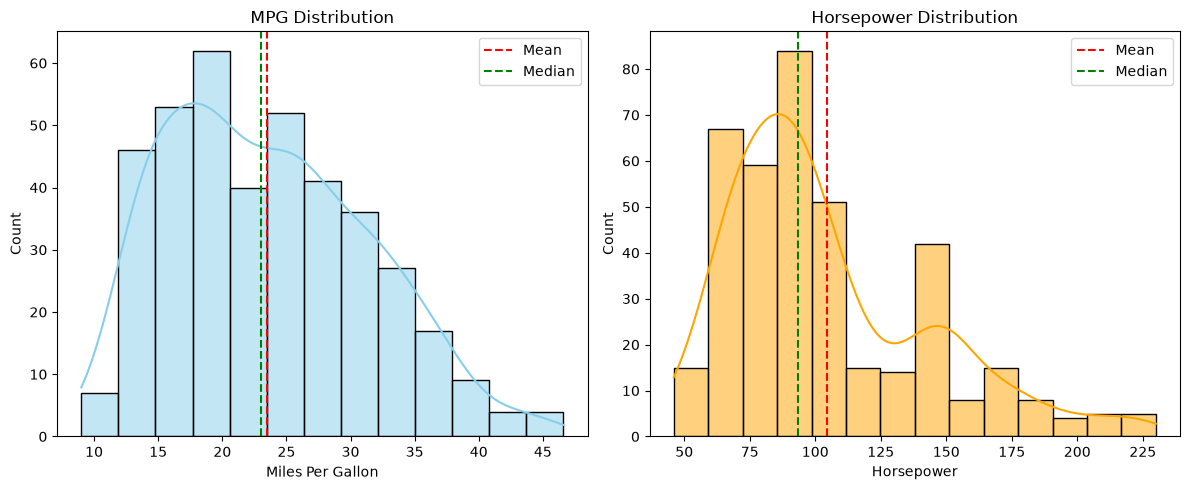

MPG Mean: 23.51
MPG Median: 23.0
Horsepower Mean: 104.47
Horsepower Median: 93.5


In [31]:

import matplotlib.pyplot as plt
import seaborn as sns

# Create two distribution plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MPG distribution
sns.histplot(
    cars["MPG"].dropna(),
    kde=True,
    ax=axes[0],
    color="skyblue"
)

axes[0].axvline(
    cars["MPG"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    cars["MPG"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("MPG Distribution")
axes[0].set_xlabel("Miles Per Gallon")
axes[0].legend()

# Horsepower distribution
sns.histplot(
    cars["Horsepower"].dropna(),
    kde=True,
    ax=axes[1],
    color="orange"
)

axes[1].axvline(
    cars["Horsepower"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[1].axvline(
    cars["Horsepower"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[1].set_title("Horsepower Distribution")
axes[1].set_xlabel("Horsepower")
axes[1].legend()

plt.tight_layout()
plt.show()

# Print statistics
print("MPG Mean:", round(cars["MPG"].mean(), 2))
print("MPG Median:", round(cars["MPG"].median(), 2))

print("Horsepower Mean:",
      round(cars["Horsepower"].mean(), 2))

print("Horsepower Median:",
      round(cars["Horsepower"].median(), 2))


#### Observation

I visualized the MPG and Horsepower distributions using histograms and KDE curves.

The MPG distribution is slightly right-skewed, with a mean of 23.51 and a median of 23.00. The Horsepower distribution is more strongly right-skewed, with a mean of 104.47 and a median of 93.50.

Since Horsepower contains higher values that affect the mean, I decided to use **median imputation** to fill the 6 missing values. The median is less sensitive to extreme values and helps preserve the original number of records.

### **Task 3.6 – Apply `SimpleImputer`**

Use Scikit-Learn's `SimpleImputer` on at least one appropriate feature.

Remember the two main stages:

1. `fit` – learn the replacement statistic from the data;
2. `transform` – replace missing values using that statistic.

You may use `fit_transform()` when appropriate, but explain what it combines.

#### Apply SimpleImputer

**Objective:** Handle missing Horsepower values using Scikit-Learn's `SimpleImputer`.

Based on the distribution analysis, I selected median imputation because the Horsepower data is right-skewed.

In this task, I will:
- Create a copy of the original dataset.
- Apply `SimpleImputer` with the median strategy.
- Replace the 6 missing Horsepower values.
- Verify that no missing values remain.
- Compare the dataset before and after imputation.

In [32]:

from sklearn.impute import SimpleImputer

# Create a copy of the dataset
cars_cleaned = cars.copy()

# Initialize SimpleImputer with median strategy
imputer = SimpleImputer(strategy="median")

# Apply median imputation to Horsepower
cars_cleaned[["Horsepower"]] = imputer.fit_transform(
    cars_cleaned[["Horsepower"]]
)

# Check missing values before imputation
print("Missing values before imputation:")
print(cars["Horsepower"].isnull().sum())

# Check missing values after imputation
print("\nMissing values after imputation:")
print(cars_cleaned["Horsepower"].isnull().sum())

# Display dataset shape
print("\nDataset shape:", cars_cleaned.shape)

# Display the median value used for imputation
print("Median used for imputation:", imputer.statistics_[0])

# Display overall missing values
print("\nRemaining missing values:")
display(cars_cleaned.isnull().sum())


Missing values before imputation:
6

Missing values after imputation:
0

Dataset shape: (398, 9)
Median used for imputation: 93.5

Remaining missing values:


MPG             0
Cylinders       0
Displacement    0
Horsepower      0
Weight          0
Acceleration    0
ModelYear       0
Origin          0
CarName         0
dtype: int64

#### Observation

I applied `SimpleImputer` with the median strategy to handle missing values in the Horsepower column.

The imputer replaced all 6 missing values with the median horsepower of 93.5. After imputation, no missing values remained in the dataset.

The dataset shape remained (398, 9), which means all records and features were preserved. Median imputation was selected because the Horsepower distribution is right-skewed.

### **Task 3.7 – Validate the Cleaned Cars Dataset**

Compare the dataset **before and after cleaning**.

Report:

- shape;
- missing-value counts;
- duplicate counts;
- descriptive statistics for selected numeric columns.

Create at least **one visualization** supporting your comparison.

#### Validate the Cleaned Dataset

In this task, I will validate the cleaned Cars dataset by:

- Comparing the number of rows and columns before and after cleaning.
- Checking whether any missing values or duplicate records remain.
- Comparing the mean and median Horsepower values.
- Visualizing the Horsepower distribution before and after imputation.
- Saving the cleaned dataset as a CSV file.

This validation helps confirm that the cleaning process preserved the dataset structure and successfully handled missing values.

In [33]:

# Compare original and cleaned datasets
validation = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing Values",
        "Duplicate Records",
        "Mean Horsepower",
        "Median Horsepower"
    ],
    "Before Cleaning": [
        cars_original.shape[0],
        cars_original.shape[1],
        cars_original.isnull().sum().sum(),
        cars_original.duplicated().sum(),
        cars_original["Horsepower"].mean(),
        cars_original["Horsepower"].median()
    ],
    "After Cleaning": [
        cars_cleaned.shape[0],
        cars_cleaned.shape[1],
        cars_cleaned.isnull().sum().sum(),
        cars_cleaned.duplicated().sum(),
        cars_cleaned["Horsepower"].mean(),
        cars_cleaned["Horsepower"].median()
    ]
})

display(validation.round(2))


,Metric,Before Cleaning,After Cleaning
0,Rows,398.00,398.0
1,Columns,9.00,9.0
2,Missing Values,6.00,0.0
3,Duplicate Records,0.00,0.0
4,Mean Horsepower,104.47,104.3
5,Median Horsepower,93.50,93.5


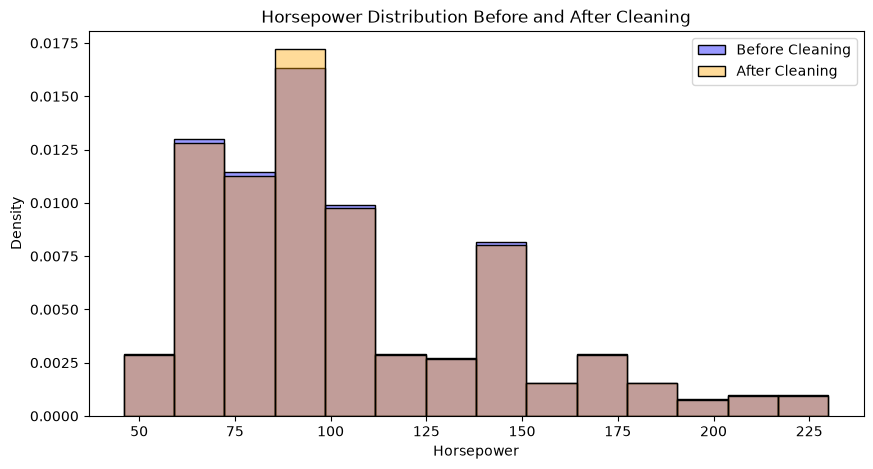

In [34]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

# Original Horsepower distribution
sns.histplot(
    cars_original["Horsepower"].dropna(),
    color="blue",
    alpha=0.4,
    label="Before Cleaning",
    stat="density"
)

# Cleaned Horsepower distribution
sns.histplot(
    cars_cleaned["Horsepower"],
    color="orange",
    alpha=0.4,
    label="After Cleaning",
    stat="density"
)

plt.title("Horsepower Distribution Before and After Cleaning")
plt.xlabel("Horsepower")
plt.ylabel("Density")
plt.legend()
plt.show()


In [35]:

from pathlib import Path

# Validate cleaned dataset
assert cars_cleaned.isnull().sum().sum() == 0, \
    "Missing values still exist."

assert cars_cleaned.duplicated().sum() == 0, \
    "Duplicate records still exist."

assert cars_cleaned.shape == (398, 9), \
    "Unexpected dataset shape."

print("All validation checks passed!")

# Create data folder if necessary
Path("data").mkdir(exist_ok=True)

# Save cleaned dataset
cars_cleaned.to_csv(
    "data/cars_cleaned.csv",
    index=False
)

print("Cleaned dataset saved to data/cars_cleaned.csv")


All validation checks passed!
Cleaned dataset saved to data/cars_cleaned.csv


#### Observation

I compared the original and cleaned Cars datasets to check whether the cleaning process was successful.

The dataset maintained its original shape of 398 rows and 9 columns. All 6 missing Horsepower values were filled using median imputation, and no duplicate records were found.

The mean Horsepower changed slightly from 104.47 to 104.30, while the median remained 93.50. The distribution graph also shows very little difference before and after cleaning.

All validation checks passed, and I saved the cleaned dataset as `cars_cleaned.csv` for future use.

### **Task 3.8 – Cars Reflection**

Answer all questions:

1. What were the main data-quality problems?
2. How many missing values did you find?
3. What happened when you dropped rows containing missing values?
4. Why might dropping entire columns be inappropriate?
5. When is mean imputation reasonable?
6. When might median be safer than mean?
7. Where would mode imputation be appropriate?
8. How did `SimpleImputer` differ from manually calling `fillna()`?
9. Did cleaning materially change the dataset statistics?
10. Which cleaning decisions would you carry forward into an ML pipeline, and why?

### Task 3.8 – Reflection

**1. What were the main data quality issues?**

The main issue was missing data in the Horsepower column. Six records had missing horsepower values. No duplicate records or invalid MPG rows were found.

**2. How many missing values were found?**

I found 6 missing values in the Horsepower column, representing 1.51% of the 398 records.

**3. What happened when missing rows were removed?**

Using `dropna()` reduced the number of rows from 398 to 392. Although it removed all missing values, it also resulted in losing six records.

**4. What happened when missing columns were removed?**

Using `dropna(axis=1)` removed the entire Horsepower column, reducing the dataset from 9 to 8 columns. This method was not suitable because Horsepower contains useful information.

**5. What is mean imputation?**

Mean imputation replaces missing numerical values with the average of the available values. However, the mean can be affected by extremely high or low values.

**6. Why did you choose median imputation?**

I selected median imputation because the Horsepower distribution was right-skewed. The median of 93.50 was less affected by high horsepower values than the mean of 104.47.

**7. When is mode imputation useful?**

Mode imputation is useful for categorical data because it replaces missing values with the most frequently occurring value. For example, it could be used for the Origin column if values were missing.

**8. How does SimpleImputer work?**

`SimpleImputer` is a Scikit-Learn tool used to fill missing values automatically. I used the median strategy to replace the six missing Horsepower values with 93.50.

**9. Did imputation change the dataset statistics?**

Yes, the mean Horsepower decreased slightly from 104.47 to 104.30, but the median remained 93.50. The overall distribution stayed almost the same.

**10. Why is data cleaning important before machine learning?**

Data cleaning improves data quality by handling missing values, duplicate records, and invalid data. It helps machine learning models work with consistent input and reduces the risk of misleading results.

### Conclusion

In this task, I learned how to identify missing values, compare different cleaning methods, apply median imputation, and validate the cleaned dataset. The final dataset contains 398 rows and 9 columns with no missing values or duplicate records.

# **Section 4 – Outlier Detection (Diabetes Dataset)**

## **Learning Topic: Outlier Detection and Treatment**

An **outlier** is an observation that differs substantially from most of the data. Outliers can result from measurement errors, data-entry problems, unusual but legitimate cases, or genuinely rare events.

Outliers matter because they can affect:

- means and standard deviations;
- correlations;
- regression coefficients;
- distance-based algorithms;
- scaling and normalization;
- model evaluation.

**Important:** Detecting an outlier does **not** automatically mean it should be deleted. You must justify treatment in the context of the data.

## **Getting the Diabetes Dataset from the Internet**

For this section, use the **Pima Indians Diabetes** CSV commonly used in introductory machine-learning exercises. The expected version has **768 observations** and these nine columns:

`Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age`, and `Outcome`.

### Recommended method — download in your browser

A public CSV copy is available here:

`https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv`

1. Open the address above in a browser.
2. Save the file as **`diabetes.csv`**.
3. Place it in your project's **`data`** folder.
4. Load the local copy:

```python
diabetes = pd.read_csv("./data/diabetes.csv")
```

### Optional Python-assisted download

```python
from pathlib import Path
import pandas as pd

Path("data").mkdir(exist_ok=True)

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
diabetes = pd.read_csv(url)
diabetes.to_csv("./data/diabetes.csv", index=False)
```

### Verify before continuing

Run:

```python
diabetes.shape
diabetes.head()
diabetes.columns
```

For the expected file, the shape should be `(768, 9)` and the columns should match the list above.

### Important data-quality warning

In this dataset, some physiological variables contain **zero values** that may represent unavailable or invalid measurements rather than plausible measurements. Do not automatically treat every zero as an outlier or delete it. Inspect the variable meaning first, document your decision, and keep the focus of this section on comparing the required outlier-detection methods.

> **Dataset-name warning:** UCI also hosts a dataset simply called **Diabetes**, but it is a different time-series dataset. For this particular lab, use the nine-column Pima-style CSV described above so your work matches the assignment.

### Dataset Description – Diabetes Prediction Dataset

For this section, we selected the **Diabetes Prediction Dataset** instead of the original Pima Indians Diabetes Dataset, following our professor's instruction to use a different dataset.

The dataset contains approximately **100,000 records and 9 columns** with information about individuals, including their age, health conditions, and diabetes status.

**Main features in the dataset:**

- **gender:** Gender of the individual.
- **age:** Age of the individual.
- **hypertension:** Indicates whether the individual has high blood pressure.
- **heart_disease:** Indicates whether the individual has heart disease.
- **smoking_history:** Smoking habits of the individual.
- **bmi:** Body Mass Index, which relates weight to height.
- **HbA1c_level:** A measure of average blood sugar levels over the past 2–3 months.
- **blood_glucose_level:** Blood glucose measurement.
- **diabetes:** Indicates whether the individual has diabetes (0 = No, 1 = Yes).

**Purpose of this analysis:**

The objective is to identify and analyze outliers in numerical features such as age, BMI, HbA1c level, and blood glucose level. We will use box plots, scatter plots, Z-Score, and Interquartile Range (IQR) methods to detect unusual values and examine how they affect the dataset.

We will also determine whether these values should be retained or treated, since an unusual medical measurement does not necessarily indicate incorrect data.

**Dataset Source:** [Diabetes Prediction Dataset – Kaggle](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset)

### **Task 4.1 – Load and Explore the Diabetes Dataset**

1. Load the Diabetes dataset from your data folder.
2. Display shape, columns, data types, and descriptive statistics.
3. Identify the numeric features you will examine for outliers.
4. Check for missing or obviously invalid values before outlier analysis.

In [14]:
# Task 4.1 - Load and inspect the alternative Diabetes dataset
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = Path("data/diabetes_prediction_dataset.csv")
if not file_path.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {file_path}. Download the CSV using the link "
        "in the Markdown cell above and place it in your project data/ folder."
    )

diabetes = pd.read_csv(file_path)
print("Shape (rows, columns):", diabetes.shape)
print("Columns:", diabetes.columns.tolist())
print("\nData types:\n", diabetes.dtypes)
print("\nFirst five rows:")
display(diabetes.head())

numeric_features = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
required = numeric_features + ["diabetes"]
missing_columns = [column for column in required if column not in diabetes.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

# Convert selected measurements safely to numeric values.
for column in numeric_features:
    diabetes[column] = pd.to_numeric(diabetes[column], errors="coerce")

print("\nMissing values per column:\n", diabetes.isna().sum())
print("\nRows with BMI <= 0:", int((diabetes["bmi"] <= 0).sum()))
print("\nDescriptive statistics for measured variables:")
display(diabetes[numeric_features].describe().T)


Shape (rows, columns): (100000, 9)
Columns: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Data types:
 gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

First five rows:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



Missing values per column:
 gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Rows with BMI <= 0: 0

Descriptive statistics for measured variables:


,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00


### **Task 4.2 – Box Plot Method**

Create box plots for selected numeric features.

Use the plots to:

- identify observations outside the whiskers;
- compare which variables appear to contain more extreme values;
- explain what the box, median, quartiles, and whiskers represent.

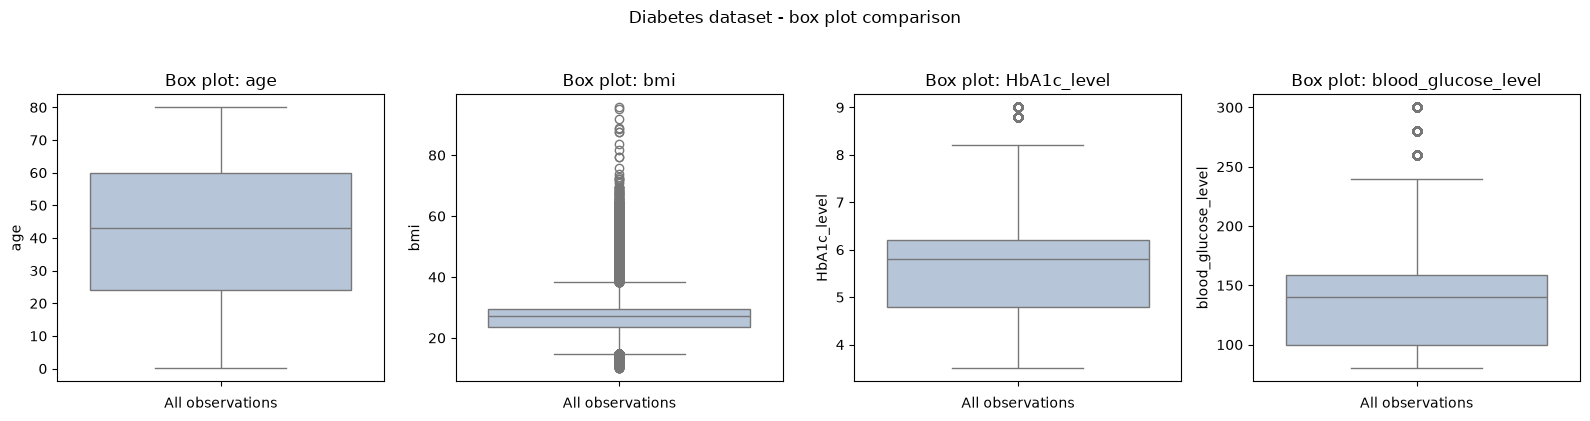

In [15]:
# Task 4.2 - Box plots for continuous numeric measurements
fig, axes = plt.subplots(1, len(numeric_features), figsize=(16, 4))
for ax, column in zip(axes, numeric_features):
    sns.boxplot(y=diabetes[column], ax=ax, color="lightsteelblue")
    ax.set_title(f"Box plot: {column}")
    ax.set_xlabel("All observations")
    ax.set_ylabel(column)
plt.suptitle("Diabetes dataset - box plot comparison", y=1.04)
plt.tight_layout()
plt.show()


### **Task 4.3 – Scatter Plot Method**

Create at least one scatter plot using two meaningful numeric features.

Use the plot to identify observations that appear isolated from the main cluster of data.

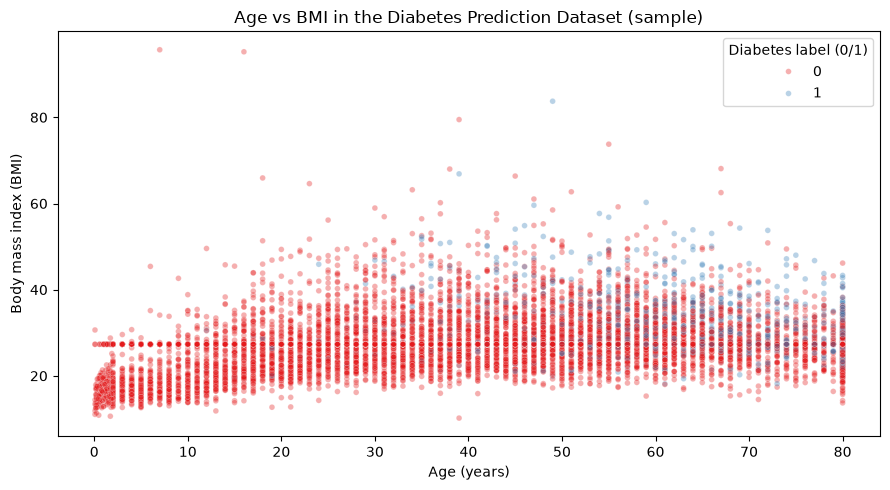

In [38]:
# Task 4.3 - Scatter plot: age compared with BMI
# Sampling makes the visualization readable; the statistical checks use all rows.
plot_data = diabetes[["age", "bmi", "diabetes"]].dropna()
plot_data = plot_data.sample(n=min(10000, len(plot_data)), random_state=42)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=plot_data, x="age", y="bmi", hue="diabetes",
    alpha=0.35, s=17, palette="Set1"
)
plt.title("Age vs BMI in the Diabetes Prediction Dataset (sample)")
plt.xlabel("Age (years)")
plt.ylabel("Body mass index (BMI)")
plt.legend(title="Diabetes label (0/1)")
plt.tight_layout()
plt.show()


### **Task 4.4 – Z-Score Method**

For a numeric feature, calculate:

\[
z = \frac{x - \mu}{\sigma}
\]

Use the conventional threshold:

\[
|z| > 3
\]

to flag potential outliers.

Report the number of observations identified.

In [39]:
# Task 4.4 - Z-Score rule for BMI: absolute Z-Score > 3
feature = "bmi"
bmi = diabetes[feature]
mean_bmi = bmi.mean()
std_bmi = bmi.std(ddof=0)  # Population standard deviation
if std_bmi == 0 or pd.isna(std_bmi):
    raise ValueError("BMI cannot be evaluated with Z-Scores: no variability.")

bmi_zscores = (bmi - mean_bmi) / std_bmi
z_outliers = bmi_zscores.abs() > 3

print(f"Mean BMI: {mean_bmi:.3f}")
print(f"Standard deviation of BMI: {std_bmi:.3f}")
print("Z-Score threshold: |z| > 3")
print("Z-Score outliers in BMI:", int(z_outliers.sum()))
print("Outlier percentage:", round(z_outliers.mean() * 100, 2), "%")
display(diabetes.loc[z_outliers, ["age", "bmi", "HbA1c_level", "blood_glucose_level"]].head())


Mean BMI: 27.321
Standard deviation of BMI: 6.637
Z-Score threshold: |z| > 3
Z-Score outliers in BMI: 1294
Outlier percentage: 1.29 %


,age,bmi,HbA1c_level,blood_glucose_level
11,54.0,54.70,6.0,100
39,34.0,56.43,6.2,200
59,67.0,63.48,8.8,155
93,38.0,55.61,6.5,130
98,30.0,50.13,6.0,100


Task 4.4 – Talking Points: Z-Score Method

We applied the Z-Score method to BMI using a threshold of |z| > 3.

The method identified 1,294 potential outliers, representing 1.29% of the dataset.

This method helps identify observations that are unusually far from the mean based on standard deviation.

### **Task 4.5 – Interquartile Range (IQR) Method**

Calculate:

\[
IQR = Q3 - Q1
\]

Then calculate:

\[
Lower\ Bound = Q1 - 1.5(IQR)
\]

\[
Upper\ Bound = Q3 + 1.5(IQR)
\]

Identify observations outside those bounds and report the outlier count.

In [40]:
# Task 4.5 - IQR method for BMI
q1 = bmi.quantile(0.25)
q3 = bmi.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

iqr_outliers = (bmi < lower_bound) | (bmi > upper_bound)
print(f"BMI Q1: {q1:.3f}")
print(f"BMI Q3: {q3:.3f}")
print(f"BMI IQR (Q3 - Q1): {iqr:.3f}")
print(f"Lower bound: {lower_bound:.3f}")
print(f"Upper bound: {upper_bound:.3f}")
print("IQR outliers in BMI:", int(iqr_outliers.sum()))
print("Outlier percentage:", round(iqr_outliers.mean() * 100, 2), "%")
display(diabetes.loc[iqr_outliers, ["age", "bmi", "HbA1c_level", "blood_glucose_level"]].head())


BMI Q1: 23.630
BMI Q3: 29.580
BMI IQR (Q3 - Q1): 5.950
Lower bound: 14.705
Upper bound: 38.505
IQR outliers in BMI: 7086
Outlier percentage: 7.09 %


,age,bmi,HbA1c_level,blood_glucose_level
11,54.0,54.70,6.0,100
24,4.0,13.99,4.0,140
39,34.0,56.43,6.2,200
59,67.0,63.48,8.8,155
93,38.0,55.61,6.5,130


Task 4.5 – Talking Points: IQR Method

We applied the IQR method to BMI using the first and third quartiles.

The calculated lower and upper boundaries were 14.705 and 38.505.

The method identified 7,086 potential outliers, representing 7.09% of the dataset.

IQR is less sensitive to extreme values because it uses quartiles instead of the mean and standard deviation.

### **Task 4.6 – Compare Detection Methods**

Create a small comparison showing the number of potential outliers identified by:

- Box Plot / IQR interpretation
- Z-Score
- IQR rule

Explain why the methods may identify different observations.

In [41]:
# Task 4.6 - Compare detection rules for the SAME variable (BMI)
# A conventional box plot uses the same 1.5 * IQR whisker convention.
method_comparison = pd.DataFrame({
    "Detection method": ["Box-plot whisker rule (BMI)", "Z-Score |z| > 3 (BMI)", "IQR 1.5 rule (BMI)"],
    "Flagged observations": [int(iqr_outliers.sum()), int(z_outliers.sum()), int(iqr_outliers.sum())],
})
method_comparison["Percent of dataset"] = (
    method_comparison["Flagged observations"] / len(diabetes) * 100
).round(2)
display(method_comparison)

print("Flagged by both Z-Score and IQR:", int((z_outliers & iqr_outliers).sum()))
print("Flagged by IQR only:", int((iqr_outliers & ~z_outliers).sum()))
print("Flagged by Z-Score only:", int((z_outliers & ~iqr_outliers).sum()))


,Detection method,Flagged observations,Percent of dataset
0,Box-plot whisker rule (BMI),7086,7.09
1,Z-Score |z| > 3 (BMI),1294,1.29
2,IQR 1.5 rule (BMI),7086,7.09


Flagged by both Z-Score and IQR: 1294
Flagged by IQR only: 5792
Flagged by Z-Score only: 0


Task 4.6 – Talking Points: Method Comparison

The Z-Score method identified 1,294 BMI outliers, while the IQR method identified 7,086.

All 1,294 Z-Score outliers were also identified by IQR, while IQR identified an additional 5,792 observations.

This comparison shows that different methods can produce different results, so the selection of an outlier detection technique depends on the data distribution and analysis requirements.

### **Task 4.7 – Treat Outliers Carefully**

Create a cleaned copy of the dataset and remove outliers **only where you can justify doing so**.

Do not overwrite the original dataframe.

Compare before and after:

- number of rows;
- mean;
- median;
- standard deviation;
- relevant visualizations.

,Before (all observations),After (IQR-filtered comparison)
Number of rows,100000.000,92914.000
Mean BMI,27.321,26.401
Median BMI,27.320,27.320
BMI standard deviation,6.637,4.893


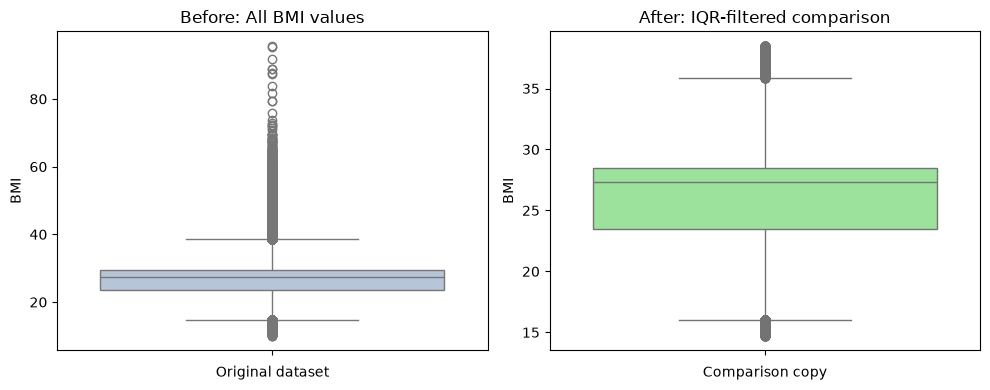

Original rows preserved: 100000
Rows flagged for investigation: 7086

Decision: Keep medically plausible extreme measurements in the retained
dataset until checked. Use the filtered copy only to illustrate how
statistical removal changes the summary and distribution.


In [42]:
# Task 4.7 - Preserve raw data and illustrate effects of removing IQR flags
# IMPORTANT: This is an educational comparison, not a claim that unusual BMIs are wrong.
diabetes_review = diabetes.copy()
diabetes_review["bmi_iqr_outlier"] = iqr_outliers

# Comparison copy only: remove BMI values flagged by the IQR rule.
diabetes_filtered = diabetes_review.loc[~diabetes_review["bmi_iqr_outlier"]].copy()

before = diabetes["bmi"]
after = diabetes_filtered["bmi"]
summary = pd.DataFrame({
    "Before (all observations)": [len(diabetes), before.mean(), before.median(), before.std()],
    "After (IQR-filtered comparison)": [len(diabetes_filtered), after.mean(), after.median(), after.std()],
}, index=["Number of rows", "Mean BMI", "Median BMI", "BMI standard deviation"])
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=before, ax=axes[0], color="lightsteelblue")
axes[0].set_title("Before: All BMI values")
axes[0].set_ylabel("BMI")
axes[0].set_xlabel("Original dataset")
sns.boxplot(y=after, ax=axes[1], color="lightgreen")
axes[1].set_title("After: IQR-filtered comparison")
axes[1].set_ylabel("BMI")
axes[1].set_xlabel("Comparison copy")
plt.tight_layout()
plt.show()

print("Original rows preserved:", len(diabetes))
print("Rows flagged for investigation:", int(diabetes_review["bmi_iqr_outlier"].sum()))
print("\nDecision: Keep medically plausible extreme measurements in the retained")
print("dataset until checked. Use the filtered copy only to illustrate how")
print("statistical removal changes the summary and distribution.")


Task 4.7 – Talking Points: Outlier Treatment

We created a separate copy of the dataset to compare the results before and after filtering IQR-identified BMI outliers.

After filtering, the number of records decreased from 100,000 to 92,914.

The mean BMI decreased from 27.321 to 26.401, while the standard deviation decreased from 6.637 to 4.893.

We preserved the original dataset because unusual medical measurements may be valid and should not be removed without investigation.

### **Task 4.8 – Diabetes Reflection**

Answer all questions:

1. What is an outlier?
2. What are at least three possible causes of outliers?
3. Which variables showed the clearest visual outliers?
4. How many observations were flagged by the Z-Score method?
5. How many were flagged by the IQR method?
6. Why can Z-Score and IQR produce different results?
7. When should an outlier be retained?
8. When might removing an outlier be justified?
9. How did removal affect the descriptive statistics?
10. How could untreated outliers affect a downstream ML model?

### Task 4.8 – Diabetes Reflection

**1. What is an outlier?**

An outlier is a value that is significantly different from most other values in a dataset. For example, a BMI value that is much higher or lower than the majority of BMI values can be considered a potential outlier.

**2. What are at least three possible causes of outliers?**

Outliers can occur due to:
- **Data entry errors:** Incorrect values entered into the dataset.
- **Measurement errors:** Problems with equipment or the data collection process.
- **Natural variation:** Genuine but unusual measurements, such as an individual with a very high BMI.

**3. Which variables showed the clearest visual outliers?**

Based on the box plots, BMI showed the clearest outliers, with several values extending beyond the upper whisker. HbA1c level and blood glucose level also showed unusually high values. Age did not show clear outliers based on the box plot.

These values are not necessarily incorrect and should be investigated before removal.

**4. How many observations were flagged by the Z-Score method?**

Using the Z-Score method with a threshold of |z| > 3, we identified **1,294 outliers** in the BMI column, representing **1.29%** of the dataset.

This method identifies values that are more than three standard deviations away from the mean.

**5. How many observations were flagged by the IQR method?**

Using the IQR method, we identified **7,086 outliers** in the BMI column, representing **7.09%** of the dataset.

The calculated lower bound was 14.705, and the upper bound was 38.505. BMI values outside this range were considered potential outliers.

**6. Why can Z-Score and IQR produce different results?**

Z-Score identifies outliers based on the mean and standard deviation, while IQR uses the first and third quartiles.

IQR is generally less affected by extreme values, whereas Z-Score can be influenced by them.

In our analysis, Z-Score identified 1,294 outliers, while IQR identified 7,086. The IQR method identified more observations because its calculated boundaries were more restrictive for our BMI data.

**7. When should an outlier be retained?**

An outlier should be retained when it represents a valid observation rather than an error.

For example, a patient with a very high BMI may have a genuine medical condition. Removing such observations could result in losing important information.

**8. When might removing an outlier be justified?**

Removing an outlier may be justified when it is confirmed to be incorrect due to data entry or measurement errors.

For example, an impossible BMI value caused by incorrect data entry may need to be corrected or removed.

However, unusual medical measurements should not be removed without proper investigation.

**9. How did removal affect the descriptive statistics?**

After removing BMI values flagged by the IQR method in a separate comparison dataset, the number of records decreased from 100,000 to 92,914.

The descriptive statistics changed as follows:

| Statistic | Before | After |
|---|---:|---:|
| Number of records | 100,000 | 92,914 |
| Mean BMI | 27.321 | 26.401 |
| Median BMI | 27.320 | 27.320 |
| Standard deviation | 6.637 | 4.893 |

The mean and standard deviation decreased after filtering, while the median remained unchanged.

This shows that extreme values can affect the mean and standard deviation more than the median.

The original dataset was preserved, and filtering was performed only for comparison.

**10. How could untreated outliers affect a downstream ML model?**

Outliers can affect machine learning models by influencing statistical calculations, feature scaling, and model training.

For example, extremely high BMI values may affect distance-based algorithms such as K-Nearest Neighbors (KNN) and influence predictions.

However, some outliers represent genuine medical conditions and may contain useful information. Therefore, outliers should be investigated before deciding whether to remove them.

### Conclusion

In this analysis, we used box plots, scatter plots, Z-Score, and IQR methods to identify potential outliers in the Diabetes Prediction Dataset.

The IQR method identified more BMI outliers than the Z-Score method. We also observed that filtering these values reduced the mean and standard deviation.

We learned that outlier detection is an important preprocessing step, but not all outliers should be removed, especially when working with medical data.

## Replicability Check

### Objective
To verify that our notebook can be executed on different computers using the dependencies listed in `requirements.txt`.

### Testing Process
1. One group member created the GitHub repository and uploaded the project files.
2. Other group members cloned the repository onto their computers.
3. We installed the required Python libraries using `pip install -r requirements.txt`.
4. We opened the notebook in Visual Studio Code and executed our assigned sections.
5. We verified that the datasets loaded and the code produced the expected outputs.

### Testing Results
Our group collaborated using the same GitHub repository and dependency file across different computers.

The assigned sections were tested by team members using their respective environments. This helped us verify that the project files and dependencies could be shared and used across different systems.

### Conclusion
The group testing process helped us evaluate the reproducibility of the project. A complete end-to-end execution of all notebook sections should also be verified to confirm full reproducibility.